<a href="https://colab.research.google.com/github/Shibainulove/6070-001-202630/blob/main/WeeklyModules/Week11/Participation_Activity_Week11_CA_Congressional_Districts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11 Participation Activity: California's congressional districts

**Qingan Xu**

This notebook maps California's congressional districts with GeoPandas, Matplotlib and Folium:

1. **The districts:** the boundaries in `california-congressional-districts.geojson`.
2. **Population overlay:** each district's population from `CA_Legislative_Districts.csv`, joined to the boundaries by district number and mapped as people per square mile.
3. **Heat map of the state:** where Californians are concentrated, as a static heat map and as an interactive map with the district boundaries and a heat layer.

**To run it:** in Colab, choose **Runtime → Run all**. The setup cell copies the data files from my GitHub repository. To run it locally, keep the two data files in the same folder as this notebook and install `geopandas`, `folium` and `scipy` if you don't have them.

## Setup

In [1]:
# Colab setup (Git_Key method). Opening this notebook from GitHub in Colab brings in only the
# .ipynb file, not the data files next to it. In Colab, this cell clones the repository with the
# GitHub token saved in Colab Secrets as Git_Key, then moves into this notebook's folder so the
# relative file paths below work as they do locally. Run locally, it changes nothing.
import os
import subprocess
from pathlib import Path

GITHUB_USER = 'Shibainulove'
REPO = '6070-001-202630'
NOTEBOOK_DIR = 'WeeklyModules/Week11'  # this notebook's folder in the repository

try:
    from google.colab import userdata
except ImportError:
    userdata = None  # not running in Colab

if userdata is None:
    print('Running locally: using the files next to this notebook')
else:
    repo_dir = Path('/content') / REPO
    if not repo_dir.exists():
        try:
            token = userdata.get('Git_Key')
        except Exception:  # no Git_Key secret, or this notebook was not given access to it
            token = ''  # cloning without a token still works while the repository is public
        login = f'{token}@' if token else ''
        url = f'https://{login}github.com/{GITHUB_USER}/{REPO}.git'
        clone = subprocess.run(['git', 'clone', '--depth', '1', url, str(repo_dir)],
                               capture_output=True, text=True,
                               env={**os.environ, 'GIT_TERMINAL_PROMPT': '0'})
        if clone.returncode != 0:
            details = clone.stderr.replace(token, '***') if token else clone.stderr
            raise RuntimeError('Could not clone the repository. In Colab Secrets (key icon), save a '
                               'GitHub token that can read it as Git_Key and turn on notebook access.\n'
                               + details)
        # Remove the token from the clone's saved remote address
        subprocess.run(['git', '-C', str(repo_dir), 'remote', 'set-url', 'origin',
                        f'https://github.com/{GITHUB_USER}/{REPO}.git'], check=True)
    os.chdir(repo_dir / NOTEBOOK_DIR)
    print('Reading files from', Path.cwd())

Running locally: using the files next to this notebook


In [2]:
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from folium.plugins import HeatMap
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch, Rectangle
from scipy.ndimage import gaussian_filter
from shapely.geometry import box
from shapely.ops import polylabel

# Both data files sit in the same folder as this notebook ('.' means this folder).
# In Colab, the setup cell above clones the repository and moves into this folder first.
DATA_DIR = Path('.')
BOUNDARIES_FILE = DATA_DIR / 'california-congressional-districts.geojson'
POPULATION_FILE = DATA_DIR / 'CA_Legislative_Districts.csv'

# Check for both files before reading either, so a missing file gives a clear message
missing = [path.name for path in (BOUNDARIES_FILE, POPULATION_FILE) if not path.exists()]
if missing:
    raise FileNotFoundError(f'Put these files in {DATA_DIR.resolve()}: {", ".join(missing)}')
print('Found', BOUNDARIES_FILE.name, 'and', POPULATION_FILE.name)

# California Albers (EPSG:3310) is an equal-area projection made for California: shapes look
# right and areas come out in true square meters, so district sizes can be compared fairly.
CA_ALBERS = 'EPSG:3310'
SQ_METERS_PER_SQ_MILE = 2_589_988.11

# Colors shared by the charts
SURFACE = '#fcfcfb'   # background
INK = '#0b0b0b'       # main text
INK_2 = '#52514e'     # secondary text and lines
NO_DATA = '#d9d8d3'   # gray for a district with no population figure
plt.rcParams.update({'figure.facecolor': SURFACE, 'savefig.facecolor': SURFACE})

Found california-congressional-districts.geojson and CA_Legislative_Districts.csv


## 1. California's congressional districts

The GeoJSON file has one feature per district: its number (`Name`) and its boundary (`geometry`), in longitude and latitude.

In [3]:
districts = gpd.read_file(BOUNDARIES_FILE)
print(districts.shape)
print('Coordinate reference system:', districts.crs)
districts.head()

(53, 4)


Coordinate reference system: EPSG:4326


,Name,description,descriptio,geometry
0,01,None,,"MULTIPOLYGON (((-120.07192 41.99495, -120.0010..."
1,02,None,,"MULTIPOLYGON (((-123.69821 41.81719, -123.6967..."
2,03,None,,"MULTIPOLYGON (((-121.667 39.30511, -121.63015 ..."
3,04,None,,"MULTIPOLYGON (((-120.37731 37.61679, -120.3823..."
4,05,None,,"MULTIPOLYGON (((-122.16384 38.64288, -122.1659..."


The two description columns are empty, so only the district number and boundary are kept. Projecting to California Albers turns the coordinates into meters, which gives each district's area.

In [4]:
districts = (
    districts.rename(columns={'Name': 'district'})[['district', 'geometry']]
    .sort_values('district', ignore_index=True)
    .to_crs(CA_ALBERS)
)
districts['area_sq_mi'] = districts.area / SQ_METERS_PER_SQ_MILE

# Check the boundaries before mapping them
assert districts['district'].is_unique, 'A district number appears more than once'
assert districts.is_valid.all(), 'Some boundaries are not valid polygons'

smallest = districts.loc[districts['area_sq_mi'].idxmin()]
largest = districts.loc[districts['area_sq_mi'].idxmax()]
print(f"{len(districts)} districts covering {districts['area_sq_mi'].sum():,.0f} square miles")
print(f"Smallest: district {smallest['district']} ({smallest['area_sq_mi']:,.0f} sq mi). "
      f"Largest: district {largest['district']} ({largest['area_sq_mi']:,.0f} sq mi)")

53 districts covering 163,695 square miles
Smallest: district 34 (48 sq mi). Largest: district 08 (33,042 sq mi)


### Map of the districts

The districts in Los Angeles, the Bay Area and San Diego are too small to see on a map of the whole state, so each of those areas gets a zoomed-in panel. The function below draws the statewide map and the three panels; the population map in part 2 reuses it.

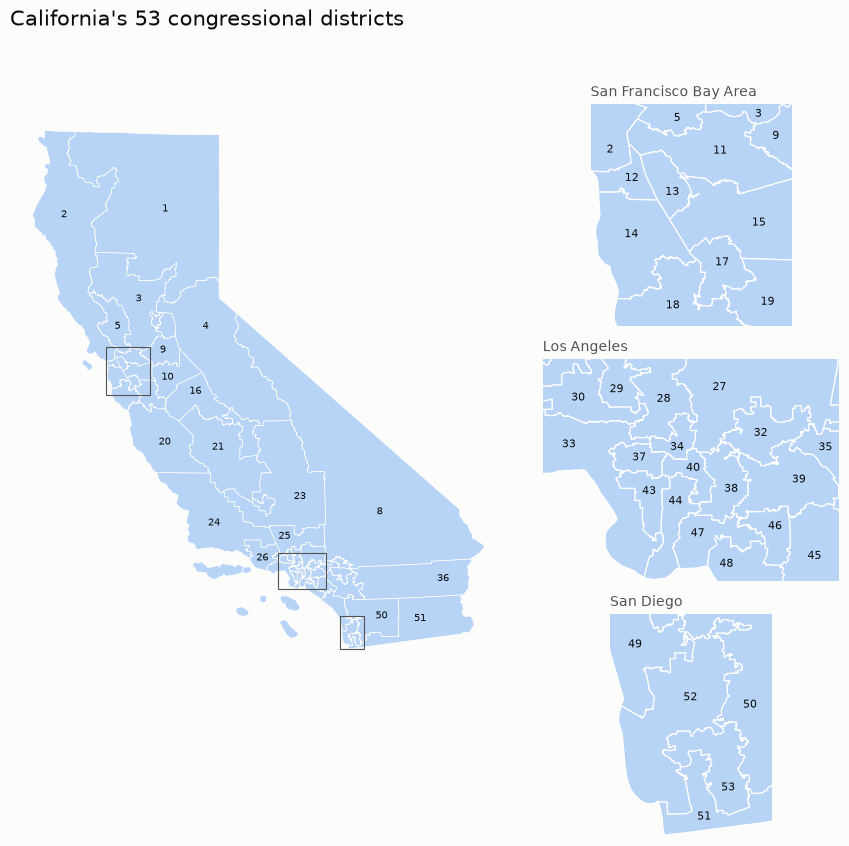

In [5]:
# The three zoomed panels: (west, south, east, north) in longitude and latitude
ZOOMS = {
    'San Francisco Bay Area': (-122.60, 37.22, -121.62, 38.08),
    'Los Angeles': (-118.70, 33.66, -117.66, 34.30),
    'San Diego': (-117.36, 32.53, -116.86, 33.12),
}
# The same windows in California Albers coordinates
ZOOM_BOUNDS = {name: gpd.GeoSeries([box(*corners)], crs='EPSG:4326').to_crs(CA_ALBERS).total_bounds
               for name, corners in ZOOMS.items()}


def label_point(shape):
    """A point well inside the largest piece of a shape, where its label can go."""
    pieces = getattr(shape, 'geoms', [shape])  # a district can have several pieces (islands)
    return polylabel(max(pieces, key=lambda piece: piece.area), tolerance=100)


def plot_district_map(frame, colors, title, label_colors=INK, min_label_area=1_200):
    """Draw the districts statewide and in the three zoomed panels, labeled with their numbers.

    colors and label_colors are one color for every district or one color per district.
    On the statewide map, only districts of at least min_label_area square miles are labeled.
    """
    label_colors = pd.Series(label_colors, index=frame.index)
    fig = plt.figure(figsize=(11, 9.5))
    grid = fig.add_gridspec(3, 2, width_ratios=[1.45, 1], hspace=0.15, wspace=0.03)
    fig.suptitle(title, x=0.125, ha='left', fontsize=15, color=INK)

    ax_state = fig.add_subplot(grid[:, 0])
    frame.plot(ax=ax_state, color=colors, edgecolor='white', linewidth=0.5)
    for i, district in frame.iterrows():
        if district['area_sq_mi'] >= min_label_area:
            point = label_point(district.geometry)
            ax_state.text(point.x, point.y, int(district['district']), ha='center', va='center',
                          fontsize=7.5, color=label_colors[i])

    for row, (name, (x0, y0, x1, y1)) in enumerate(ZOOM_BOUNDS.items()):
        ax = fig.add_subplot(grid[row, 1])
        frame.plot(ax=ax, color=colors, edgecolor='white', linewidth=0.9)
        # Label a district at the center of its visible part if most of it is in the panel
        # or it fills at least 2% of the panel
        window = box(x0, y0, x1, y1)
        for i, district in frame.iterrows():
            visible = district.geometry.intersection(window)
            if visible.area >= 0.5 * district.geometry.area or visible.area >= 0.02 * window.area:
                point = label_point(visible)
                ax.text(point.x, point.y, int(district['district']), ha='center', va='center',
                        fontsize=8, color=label_colors[i])
        ax.set_xlim(x0, x1)
        ax.set_ylim(y0, y1)
        ax.set_title(name, loc='left', fontsize=10, color=INK_2)
        ax.set_axis_off()
        # Outline the panel's area on the statewide map
        ax_state.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=INK_2, linewidth=0.8))

    ax_state.set_axis_off()
    ax_state.set_anchor('N')  # top-align the state, leaving room for a legend at the bottom left
    return fig, ax_state


plot_district_map(districts, colors='#b7d3f6', title="California's 53 congressional districts")
plt.show()

The file has **53 districts**. California had 53 seats in the House of Representatives from 2003 to 2023 and has had 52 since the 2022 election, so these are older boundaries (part 2 shows which ones). They range from 48 square miles (district 34, in central Los Angeles) to more than 33,000 (district 8, covering the eastern Sierra and the Mojave Desert). Districts are drawn to hold equal numbers of people, so the smallest ones are where people live most densely: the Los Angeles basin, the Bay Area and San Diego.

## 2. Overlay the population of each district

`CA_Legislative_Districts.csv` has one row per congressional district, with its population (`POPULATION`), its area in square miles (`AREA`) and citizen voting-age population figures.

In [6]:
# Read DISTRICT as text so '01' keeps its leading zero and matches the GeoJSON's district numbers
population = pd.read_csv(POPULATION_FILE, dtype={'DISTRICT': str})
print(population.shape)
population[['DISTRICT', 'NAME', 'POPULATION', 'IDEAL_VALU', 'DEVIATION', 'AREA']].head()

(52, 25)


,DISTRICT,NAME,POPULATION,IDEAL_VALU,DEVIATION,AREA
0,01,MTCAP,760066,760066,0,27014.63
1,10,STANI,760066,760066,0,560.65
2,11,COCO,760067,760066,1,226.43
3,12,SF,760065,760066,-1,141.25
4,13,OKLND,760065,760066,-1,6346.92


In [7]:
print(f"{len(population)} districts, {population['POPULATION'].sum():,} people in total")
print(f"Population per district: {population['POPULATION'].min():,} to {population['POPULATION'].max():,} "
      f"(ideal value: {population['IDEAL_VALU'].iloc[0]:,})")

52 districts, 39,523,437 people in total
Population per district: 760,065 to 760,067 (ideal value: 760,066)


Every district has 760,066 people, give or take one. Under the "one person, one vote" rule, congressional districts in a state must have equal populations, so the ideal value is the state's population divided by the number of districts: 39,523,437 / 52.

### Join the population to the boundaries

The two files share the district number (`district` in the GeoJSON, `DISTRICT` in the CSV). A left join keeps every boundary and adds its row from the CSV; `indicator=True` records which districts found a match.

In [8]:
merged = districts.merge(
    population[['DISTRICT', 'POPULATION', 'AREA']],
    how='left', left_on='district', right_on='DISTRICT',
    validate='one_to_one',  # stop if a district number appears twice in either file
    indicator=True,
)
print(merged['_merge'].value_counts().to_string())
print('Districts with no population row:', merged.loc[merged['_merge'] == 'left_only', 'district'].tolist())

_merge
both          52
left_only      1
right_only     0
Districts with no population row: ['53']


### Data check: do the two files describe the same districts?

District 53 has no row because the CSV has only 52 districts. The CSV also gives each district's area, so comparing it with the area measured from the GeoJSON boundary shows whether a district number means the same piece of California in both files.

In [9]:
area_check = merged.dropna(subset=['AREA'])[['district', 'area_sq_mi', 'AREA']].copy()
area_check['ratio'] = area_check['area_sq_mi'] / area_check['AREA']
same_size = area_check['ratio'].between(0.9, 1.1)
print(f'Districts whose two areas agree within 10%: {same_size.sum()} of {len(area_check)}')

# The eight biggest disagreements, in either direction
biggest_gaps = np.log(area_check['ratio']).abs().nlargest(8).index
area_check.loc[biggest_gaps].rename(columns={
    'area_sq_mi': 'GeoJSON area (sq mi)', 'AREA': 'CSV AREA (sq mi)', 'ratio': 'GeoJSON / CSV',
}).set_index('district').round(2)

Districts whose two areas agree within 10%: 12 of 52


,GeoJSON area (sq mi),CSV AREA (sq mi),GeoJSON / CSV
district,,,
08,33041.85,614.83,53.74
13,145.94,6346.92,0.02
36,5990.33,194.68,30.77
51,5127.79,191.15,26.83
48,254.85,3636.15,0.07
21,6743.74,893.26,7.55
25,1702.46,12356.44,0.14
50,2804.20,412.18,6.80


Only 12 of the 52 districts are about the same size in both files, and some are wildly different: district 8 covers 33,042 square miles in the GeoJSON but 615 in the CSV. **The two files describe different district maps:**

- The **GeoJSON** has the 53 districts drawn after the 2010 Census and used in the 2012–2020 elections.
- The **CSV** has the 52 districts drawn after the 2020 Census, when California lost a seat, and used since the 2022 election. Its 760,066 people per district come from the 2020 Census.

Redistricting moved and renumbered almost every district, so joining on the number pairs most CSV rows with a different part of the state. The CSV's `NAME` column seems to be left over from the older map: district 36 is named `COACH`, which fits the GeoJSON's district 36 (the Coachella Valley and the desert east of it), not the 195-square-mile district 36 described by the rest of the CSV row.

**What this means for the overlay:** columns that describe a district's territory, such as `AREA` and the voting-age population, can't be laid over these boundaries. Population can, approximately, because every district in either map is drawn to the same population. Spread over 53 districts instead of 52, the state's 39.5 million people come to 745,725 per district on average, 2% less than the CSV's figure, though populations shifted between districts over the decade. So the maps below divide the CSV population by the area of each GeoJSON boundary, and show district 53 as having no data.

In [10]:
# People per square mile: the CSV population divided by the area of the GeoJSON boundary
merged['people_per_sq_mi'] = merged['POPULATION'] / merged['area_sq_mi']

densest = merged.loc[merged['people_per_sq_mi'].idxmax()]
sparsest = merged.loc[merged['people_per_sq_mi'].idxmin()]
print(f"From {sparsest['people_per_sq_mi']:,.0f} people per sq mi (district {sparsest['district']}) "
      f"to {densest['people_per_sq_mi']:,.0f} (district {densest['district']})")

From 23 people per sq mi (district 08) to 15,845 (district 34)


### Population map

The density runs from about 20 to 16,000 people per square mile, so the map groups the districts into seven classes on a roughly logarithmic scale, light blue (sparse) to dark blue (dense).

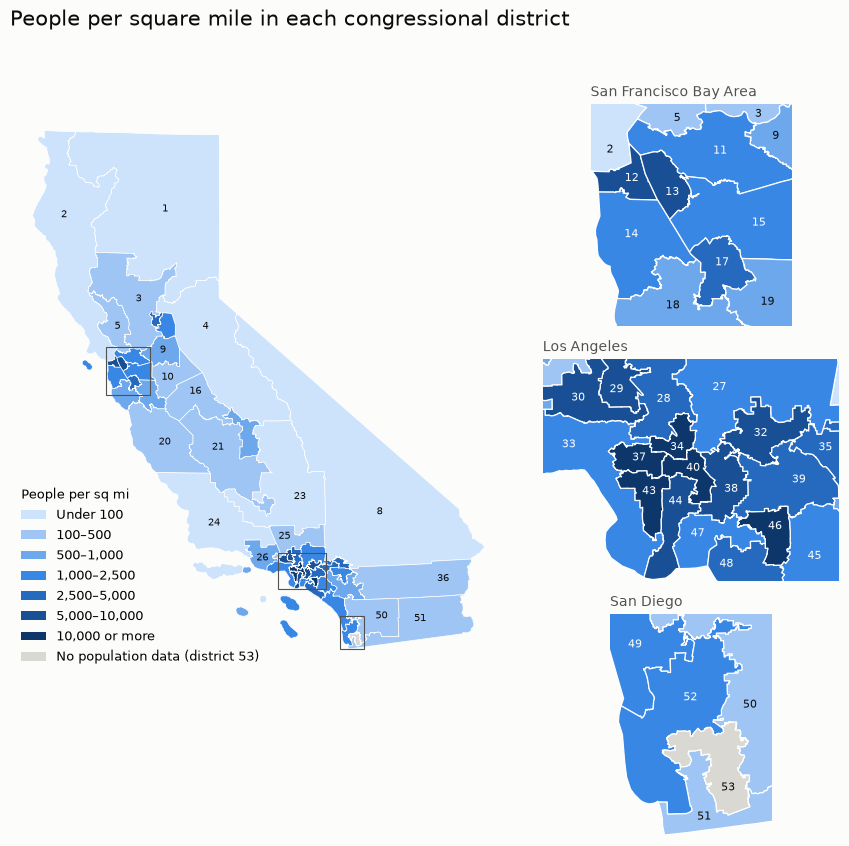

In [11]:
BREAKS = [0, 100, 500, 1_000, 2_500, 5_000, 10_000, np.inf]
CLASS_LABELS = ['Under 100', '100–500', '500–1,000', '1,000–2,500', '2,500–5,000', '5,000–10,000', '10,000 or more']
BLUES = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']

# Class number 0-6 for each district (NaN for district 53, which has no population)
density_class = pd.cut(merged['people_per_sq_mi'], BREAKS, labels=False, right=False)
fill_colors = density_class.map(lambda c: NO_DATA if pd.isna(c) else BLUES[int(c)])
label_colors = density_class.map(lambda c: 'white' if c >= 3 else INK)  # white numbers on dark blues

fig, ax_state = plot_district_map(merged, fill_colors, 'People per square mile in each congressional district',
                                  label_colors=label_colors)
legend_items = [Patch(facecolor=color, label=label) for color, label in zip(BLUES, CLASS_LABELS)]
legend_items.append(Patch(facecolor=NO_DATA, label='No population data (district 53)'))
ax_state.legend(handles=legend_items, title='People per sq mi', loc='lower left', frameon=False,
                fontsize=9, title_fontsize=9, alignment='left')
plt.show()

The table below holds the numbers behind the map: the five densest and five least dense districts.

In [12]:
columns = {'district': 'District', 'POPULATION': 'Population', 'area_sq_mi': 'Area (sq mi)',
           'people_per_sq_mi': 'People per sq mi'}
ranked = (merged.dropna(subset=['POPULATION'])
          .sort_values('people_per_sq_mi', ascending=False)[list(columns)]
          .rename(columns=columns)
          .set_index('District')
          .round(0).astype(int))

sparse = ranked['People per sq mi'] < 100
print(f"The {sparse.sum()} districts with fewer than 100 people per sq mi cover "
      f"{ranked.loc[sparse, 'Area (sq mi)'].sum() / districts['area_sq_mi'].sum():.0%} of California's area")
pd.concat([ranked.head(5), ranked.tail(5)])

The 6 districts with fewer than 100 people per sq mi cover 66% of California's area


,Population,Area (sq mi),People per sq mi
District,,,
34,760067,48,15845
37,760066,55,13721
40,760066,58,13022
43,760067,72,10520
46,760067,73,10462
23,760066,9937,76
04,760065,13168,58
02,760067,14544,52
01,760066,28840,26


Because every district holds about the same number of people, a district's density depends only on its size. The five densest districts, four in Los Angeles County and one (46) in Orange County, have more than 10,000 people per square mile. At the other end, six districts in the north, the Sierra Nevada, the Central Coast and the deserts have fewer than 100 people per square mile. Together they cover two-thirds of the state but hold only about 11% of its people.

## 3. Heat map of the state

A heat map shows where people are concentrated without the district lines getting in the way. The CSV gives one population figure per district, not where people live inside it, so both heat maps spread each district's population evenly over its area and then blur it. The hot spots are therefore districts that are small and crowded; the maps can't show differences within a district.

### Static heat map

The state is covered with a grid of 2 km cells. Each cell takes the density of the district its center falls in, and a Gaussian blur (6 km) smooths the values across district lines. The blur averages only cells that have a value, so the coast and district 53 don't drag down the cells next to them.

In [13]:
# 1. A grid of 2 km cells over the state, and the district each cell's center falls in
CELL = 2_000  # meters
west, south, east, north = merged.total_bounds
x = np.arange(west, east, CELL) + CELL / 2
y = np.arange(south, north, CELL) + CELL / 2
grid_x, grid_y = np.meshgrid(x, y)
cells = gpd.GeoDataFrame(geometry=gpd.points_from_xy(grid_x.ravel(), grid_y.ravel()), crs=CA_ALBERS)
cells = cells.sjoin(merged[['people_per_sq_mi', 'geometry']], how='left', predicate='within')
cells = cells[~cells.index.duplicated()].sort_index()  # one row per cell, in grid order
assert len(cells) == grid_x.size

# Density per cell: NaN outside California and in district 53
density = cells['people_per_sq_mi'].to_numpy().reshape(grid_x.shape)
has_value = ~np.isnan(density)

# 2. Blur, dividing by the blurred has_value mask so empty cells don't count as zeros
SMOOTHING = 3  # cells, so 6 km
with np.errstate(invalid='ignore'):  # 0/0 far out at sea, where no cell has a value
    heat = gaussian_filter(np.where(has_value, density, 0), SMOOTHING) / gaussian_filter(has_value.astype(float), SMOOTHING)
heat[~has_value] = np.nan  # leave the ocean, the neighboring states and district 53 blank
print(f'{has_value.sum():,} grid cells with a value')

105,917 grid cells with a value


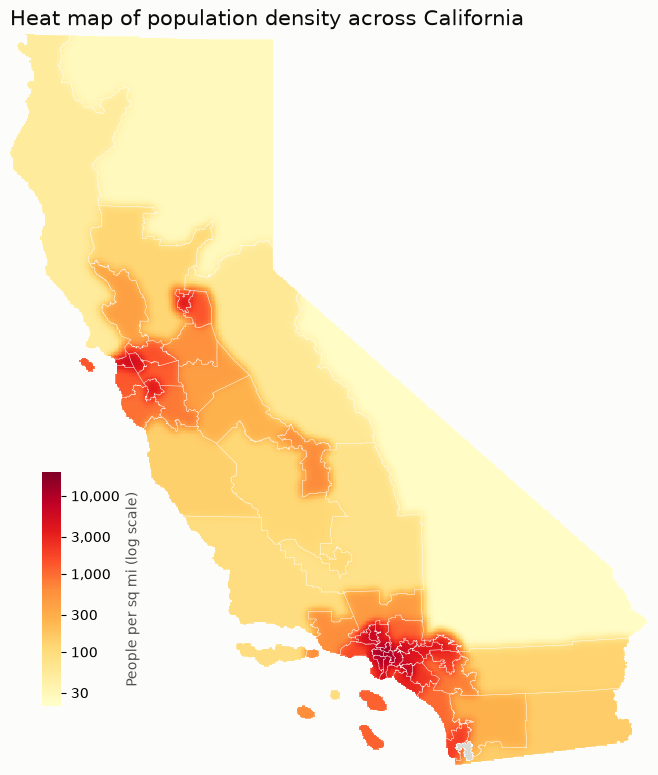

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 9.5))
image = ax.imshow(heat, extent=(x[0] - CELL / 2, x[-1] + CELL / 2, y[0] - CELL / 2, y[-1] + CELL / 2),
                  origin='lower', cmap='YlOrRd', norm=LogNorm(vmin=20, vmax=20_000), interpolation='nearest')
merged[merged['POPULATION'].isna()].plot(ax=ax, color=NO_DATA)   # district 53
merged.boundary.plot(ax=ax, color='white', linewidth=0.3, alpha=0.7)  # district lines, for reference

# Color scale in the open ocean at the lower left, with plain-number ticks
color_scale = fig.colorbar(image, cax=ax.inset_axes([0.05, 0.08, 0.03, 0.32]))
color_scale.set_ticks([30, 100, 300, 1_000, 3_000, 10_000])
color_scale.set_ticklabels(['30', '100', '300', '1,000', '3,000', '10,000'])
color_scale.set_label('People per sq mi (log scale)', color=INK_2)
color_scale.outline.set_visible(False)
color_scale.ax.minorticks_off()

ax.set_title('Heat map of population density across California', loc='left', fontsize=15, color=INK)
ax.set_axis_off()
plt.show()

The hottest area is the Los Angeles basin, with the heat spreading south into Orange County and east into the Inland Empire. The Bay Area is the second hot spot, followed by Sacramento and San Diego. San Diego looks cooler than it is, because its densest district (53) has no population figure. A band of warmer districts runs down the Central Valley around Stockton, Modesto and Fresno, while the far north, the mountains and the deserts stay pale.

### Interactive map: the districts with a heat layer

Hover over a district to see its population, area and density, and use the layer control (top right) to turn the heat layer or the district lines on and off.

The heat layer is built from random points, one for every 2,000 residents, scattered evenly inside each district (a fixed random seed makes the map the same on every run). Folium's heat map is relative: the densest spot in view is red. Statewide, that's Los Angeles; zoom in on another region and the colors rescale to it. The map needs an internet connection for the base map. It shows in Colab and Jupyter, but not in GitHub's notebook preview.

In [15]:
# The districts in longitude/latitude for the web map. Simplifying the boundaries (to about 200 m)
# keeps the map quick to load.
web_districts = merged.to_crs('EPSG:4326')
web_districts['geometry'] = web_districts.simplify(0.002)
web_districts = web_districts.assign(
    population=web_districts['POPULATION'].map(lambda v: 'no data' if pd.isna(v) else f'{v:,.0f}'),
    area=web_districts['area_sq_mi'].map('{:,.0f} sq mi'.format),
    density=web_districts['people_per_sq_mi'].map(lambda v: 'no data' if pd.isna(v) else f'{v:,.0f}'),
)[['district', 'population', 'area', 'density', 'geometry']]

# Heat points: one per 2,000 residents, placed at random inside each district.
# The points are drawn in California Albers so that they're spread evenly by area.
PEOPLE_PER_POINT = 2_000
rng = np.random.default_rng(611)
with_population = merged.dropna(subset=['POPULATION'])
points = pd.concat([
    gpd.GeoSeries([shape], crs=CA_ALBERS).sample_points(round(people / PEOPLE_PER_POINT), rng=rng)
    for shape, people in zip(with_population.geometry, with_population['POPULATION'])
]).explode(index_parts=False).to_crs('EPSG:4326')
heat_points = np.column_stack([points.y, points.x]).round(3)  # [latitude, longitude], to about 100 m
print(f'{len(heat_points):,} heat points')

19,760 heat points


In [16]:
ESRI_GRAY = 'https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}'
# Heat colors from yellow to dark red, matching the static heat map
HEAT_COLORS = {0.1: '#fed976', 0.3: '#feb24c', 0.5: '#fd8d3c', 0.75: '#f03b20', 1.0: '#bd0026'}

heat_map = folium.Map(location=[37.2, -119.4], zoom_start=6, tiles=None, control_scale=True)
folium.TileLayer(ESRI_GRAY, attr='Tiles © Esri — Esri, DeLorme, NAVTEQ', control=False).add_to(heat_map)

folium.GeoJson(
    web_districts,
    name='Congressional districts',
    style_function=lambda feature: {'color': INK_2, 'weight': 0.8, 'fillOpacity': 0},
    highlight_function=lambda feature: {'color': INK, 'weight': 2.5},
    tooltip=folium.GeoJsonTooltip(
        fields=['district', 'population', 'area', 'density'],
        aliases=['District', 'Population (CSV)', 'Area', 'People per sq mi'],
    ),
).add_to(heat_map)

HeatMap(heat_points.tolist(), name='Population heat map', radius=14, blur=10, min_opacity=0.05,
        max_zoom=8, gradient=HEAT_COLORS).add_to(heat_map)
folium.LayerControl(collapsed=False).add_to(heat_map)
heat_map

## Summary

- **The districts:** the GeoJSON has California's 53 congressional districts from the 2012–2020 elections, from 48 square miles in central Los Angeles to more than 33,000 in the eastern deserts.
- **Population overlay:** in the CSV, every district has 760,066 people (±1), since districts must have equal populations. With population held equal, density depends only on a district's size: from about 20 people per square mile in the desert to almost 16,000 in Los Angeles.
- **Data quality:** the two files come from different redistricting rounds. The CSV describes the 52 districts drawn in 2021, so district numbers don't match the same territory, and only 12 of 52 districts have similar areas in both files. Joining on the number works for population, which is equal by design, but not for columns tied to a district's territory. Boundaries for the 2021 districts would be needed for an exact overlay.
- **Heat map:** Californians are concentrated in the Los Angeles basin and the Bay Area, then Sacramento, San Diego and the Central Valley cities. Six sparse districts cover two-thirds of the state.